# Mitigating noise in non-unital circuits

The collisional cycle is `evolve → measure every ancilla → reset it to` $|0\rangle$. Discarding the
outcome makes measure+reset a **reset channel**, sending $I/2\mapsto|0\rangle\langle0|$ — so the cycle
$\mathcal U$ is **not unital**, and the one-line absorbing-state correction does not apply to it.

Assume global depolarizing $\mathcal D_\lambda(\rho)=(1-\lambda)\rho+\lambda I/d$ once per cycle, and an
absorbing state $\rho_{\rm abs}$ invariant under $\mathcal U$ with $\mathrm{Tr}(n\rho_{\rm abs})=0$. Then

$$\rho^{(k)}_{\rm phys}=(1-\lambda)^k\rho^{(k)}_{\rm ideal}+\sigma^{(k)},\qquad
\rho^{(k)}_{\rm abs}=(1-\lambda)^k\rho_{\rm abs}+\sigma^{(k)}$$

with the **same** $\sigma^{(k)}$ — it depends only on $\mathcal U$ and $\lambda$, never on the initial
state. That is the whole trick. Subtracting cancels it exactly:

$$y^{(k)}_{\rm phys}-y^{(k)}_{\rm abs}=(1-\lambda)^k\,y^{(k)}_{\rm ideal}\tag{1}$$

Recovering $y_{\rm ideal}$ then needs the scaling factor $(1-\lambda)^k$, learned from an $\Omega=0$
calibration run (§4). Everything here is trajectory Monte Carlo, so every number carries shot noise; the
sense in which the correction is *exact* is that it is **unbiased** (§7), backed by an exact algebraic
check on a synthetic model (§9).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt

from qaravan.applications import (
    collisional_dqc,
    dissipative_ising_layer,
    interleaved_collisional_layout,
    qcp_layer,
)
from qaravan.backends.statevector import Statevector
from qaravan.core.noise import DepolarizingNoise
from qaravan.core.observables import NumberOperator
from qaravan.plot import set_style

set_style()
np.set_printoptions(precision=4, suppress=True)

NUM_SYSTEM = 3
NUM_SITES = 2 * NUM_SYSTEM
OMEGA = 0.8
PHI = 0.7
ERROR_RATE = 0.03
NUM_CYCLES = 10

system_sites, all_ancillas, all_pairs = interleaved_collisional_layout(NUM_SYSTEM)

# Couple every other system qubit. Uncoupled sites see a = 1, which closes the absorbing
# recursion analytically and gives an assumption-free probe of lambda in section 4.
coupled_pairs = all_pairs[::2]
measured_ancillas = [ancilla for _, ancilla in coupled_pairs]
coupled_system = [site for site, _ in coupled_pairs]
uncoupled_system = [site for site in system_sites if site not in coupled_system]

site_number = {site: NumberOperator(NUM_SITES, qubits=[site]) for site in system_sites}
coupled_cols = [system_sites.index(site) for site in coupled_system]
uncoupled_cols = [system_sites.index(site) for site in uncoupled_system]

LAMBDA = 4**NUM_SITES * ERROR_RATE / (4**NUM_SITES - 1)
cycles = np.arange(1, NUM_CYCLES + 1)

print("system   ", system_sites)
print("coupled  ", coupled_system, "-> ancillas", measured_ancillas)
print("uncoupled", uncoupled_system, "(a = 1, assumption-free probe)")
print(f"\np = {ERROR_RATE}  ->  lambda = {LAMBDA:.5f}")

system    [0, 2, 4]
coupled   [0, 4] -> ancillas [1, 5]
uncoupled [2] (a = 1, assumption-free probe)

p = 0.03  ->  lambda = 0.03001


## 1. Why these circuits qualify

**The vacuum is absorbing — for QCP, not for the Ising model.** `qcp_layer` builds its bonds from `CRX`,
and a controlled gate whose control sits in $|0\rangle$ is the identity; `XY` preserves excitation number,
so it fixes $|00\rangle$ too. The transverse field in `dissipative_ising_layer`, $\Omega\sum_i X_i$,
instead drives population *out* of the vacuum. So the technique applies to QCP, and the Ising model is
excluded — its vacuum is not invariant, so there is no $\rho_{\rm abs}$ to subtract.

**Catches:** a wrong absorbing state, or picking the model whose vacuum is not invariant.
**Does not catch:** anything about the mitigation arithmetic itself.

In [2]:
def density_after_one_cycle(system_layer, initial):
    """Per-site system density after a single noiseless cycle."""
    dqc = collisional_dqc(system_layer, measured_ancillas, coupled_pairs, PHI, 1, NUM_SITES)
    final, _ = dqc.execute(initial, measurement_rng=np.random.default_rng(0))
    return np.array([final.expectation(site_number[site]).real for site in system_sites])


vacuum = Statevector(bitstring="0" * NUM_SITES)
qcp = qcp_layer(system_sites, OMEGA, dt=1.0)
ising = dissipative_ising_layer(system_sites, OMEGA, 0.3, dt=1.0)

qcp_after = density_after_one_cycle(qcp, vacuum)
ising_after = density_after_one_cycle(ising, vacuum)

print(f"QCP   density after one cycle from vacuum: {qcp_after}")
print(f"Ising density after one cycle from vacuum: {ising_after}")

assert np.allclose(qcp_after, 0.0, atol=1e-12), "QCP vacuum must be absorbing"
assert not np.allclose(ising_after, 0.0, atol=1e-6), "Ising vacuum should NOT be absorbing"
print("\nQCP vacuum is invariant, Ising vacuum is not -- QCP from here on.")

QCP   density after one cycle from vacuum: [0. 0. 0.]
Ising density after one cycle from vacuum: [0.3828 0.5146 0.    ]

QCP vacuum is invariant, Ising vacuum is not -- QCP from here on.


## 2. Noise model: one depolarizing channel per cycle

`StatevectorSimulator` samples a fresh Pauli after **every layer** by default, and a round's layer count
depends on $\Omega$: three with a QCP layer present, one or two without, because at $\Omega=0$ the reset
`X` gates have no system layer to pack into. The effective rate per cycle would then depend on $\Omega$,
and a scaling factor calibrated at $\Omega=0$ would not transfer to $\Omega\neq0$ — which is exactly what
§4 relies on.

The derivation assumes the noise is a property of the device, not of the circuit being run. Setting
`DepolarizingNoise(..., placement="circuit")` samples one global Pauli per `run()`, and since `DynamicCircuit.execute`
calls the simulator once per round, that is one channel per cycle, independent of layer count.

`DepolarizingNoise(n, p)` uses the Pauli-twirl form $(1-p)\rho+\frac{p}{4^n-1}\sum_{P\neq I}P\rho P^\dagger$.
Because $\frac{1}{4^n}\sum_{\rm all\,P}P\rho P^\dagger=I/d$, that is the same channel as
$(1-\lambda)\rho+\lambda I/d$ with $\lambda=\frac{4^n}{4^n-1}p$ — the conversion applied above.

In [3]:
def layer_counts(system_layer):
    """Layers in a measured round, per measurement outcome."""
    dqc = collisional_dqc(system_layer, measured_ancillas, coupled_pairs, PHI, 4, NUM_SITES)
    measured_round = next(rnd for rnd in dqc.rounds if rnd.meas_sites)
    counts = {}
    for bits in range(2 ** len(measured_round.meas_sites)):
        outcome = format(bits, f"0{len(measured_round.meas_sites)}b")
        circuit = measured_round.decoder(outcome)
        circuit.construct_layers()
        counts[outcome] = len(circuit.layers)
    return counts


print(f"layers per measured round, QCP:      {layer_counts(qcp)}")
print(f"layers per measured round, Omega=0:  {layer_counts([])}")
print("\nLayer count depends on Omega (and on the outcome at Omega=0), which is why noise")
print('is injected per cycle via noise placement="circuit" rather than per layer.')

layers per measured round, QCP:      {'00': 5, '01': 5, '10': 5, '11': 5}
layers per measured round, Omega=0:  {'00': 1, '01': 2, '10': 2, '11': 2}

Layer count depends on Omega (and on the outcome at Omega=0), which is why noise
is injected per cycle via noise placement="circuit" rather than per layer.


In [4]:
def run_density(system_layer, bitstring, num_trajectories, seed, noise=None):
    """Per-site density after each cycle, averaged over trajectories.

    Returns (mean, standard_error), each shaped (NUM_CYCLES, len(system_sites)).
    noise=None runs the noiseless protocol, where the spread comes from measurement alone.
    """
    dqc = collisional_dqc(
        system_layer, measured_ancillas, coupled_pairs, PHI, NUM_CYCLES, NUM_SITES
    )
    initial = Statevector(bitstring=bitstring)
    rng = np.random.default_rng(seed)
    kwargs = {}
    if noise is not None:
        kwargs = dict(
            noise_model=noise,
            noise_rng=rng,
        )

    trace = []

    def record(_, state):
        trace.append([state.expectation(site_number[site]).real for site in system_sites])

    total = np.zeros((NUM_CYCLES, len(system_sites)))
    total_square = np.zeros_like(total)
    for _ in range(num_trajectories):
        trace.clear()
        dqc.execute(initial, measurement_rng=rng, observer=record, **kwargs)
        values = np.array(trace[:NUM_CYCLES])
        total += values
        total_square += values**2

    mean = total / num_trajectories
    variance = np.maximum(total_square / num_trajectories - mean**2, 0.0)
    return mean, np.sqrt(variance / num_trajectories)


EXCITED = "10" * NUM_SYSTEM
VACUUM = "0" * NUM_SITES
noise = DepolarizingNoise(NUM_SITES, ERROR_RATE, placement="circuit")

## 3. The problem

Noiseless, the protocol drains the system to $|0\cdots0\rangle$ and stops there. Under depolarizing noise
the absorbing state stops being absorbing: population is re-injected every cycle, and the density settles
on a plateau above zero. The noisy curve is not a rescaled copy of the ideal one — it carries an additive
floor, which is exactly $\mathrm{Tr}(n\sigma^{(k)})$.

final ideal density 0.0784
final noisy density 0.1154
absorbing floor     0.0617


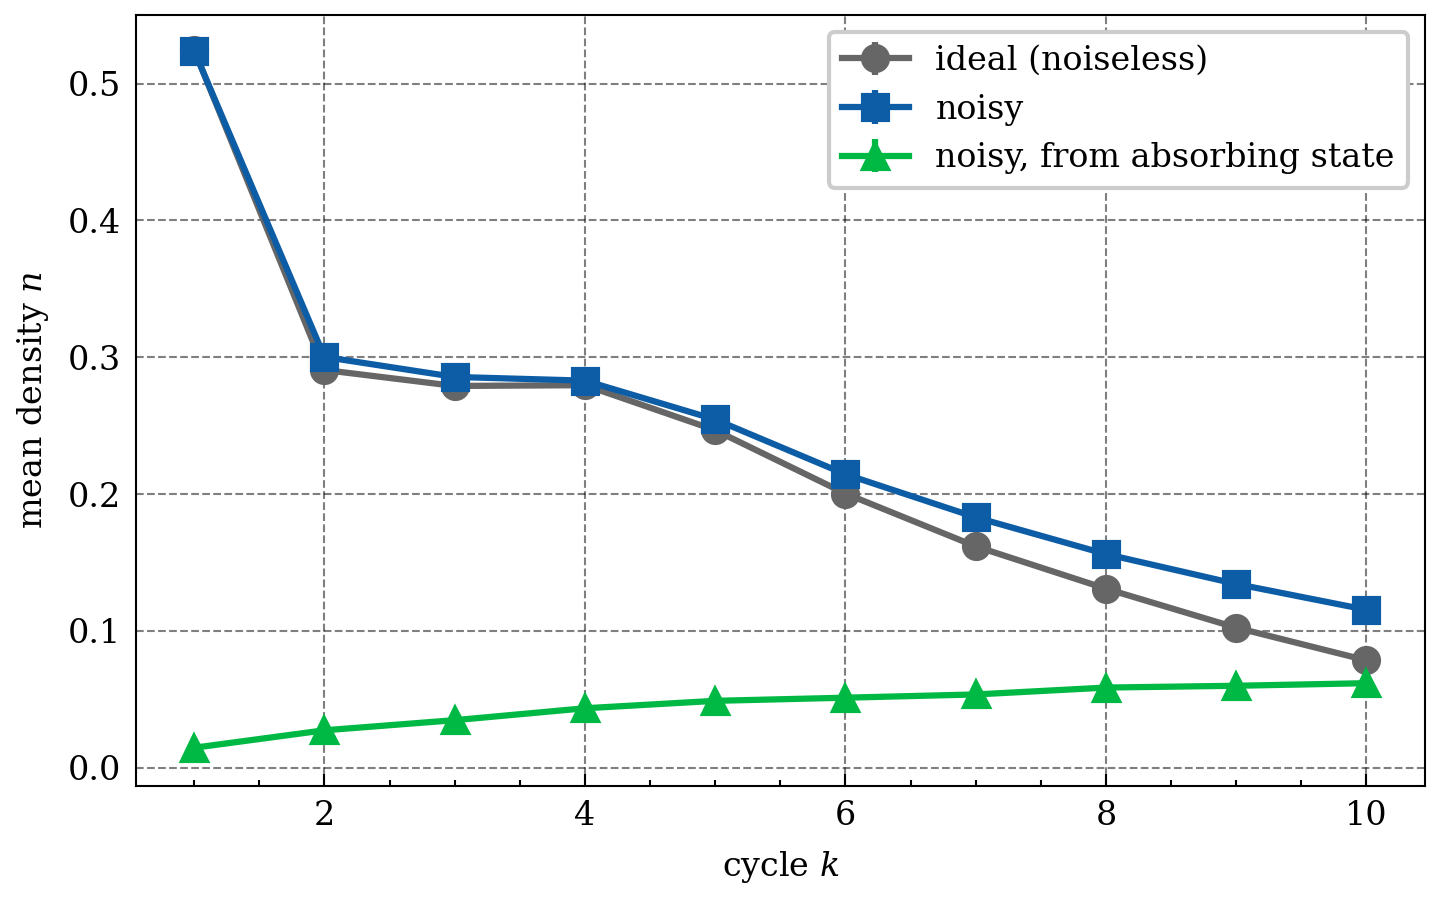

In [5]:
IDEAL_TRAJECTORIES = 12000
TRAJECTORIES = 3000

ideal, ideal_err = run_density(qcp, EXCITED, IDEAL_TRAJECTORIES, seed=11)
phys, phys_err = run_density(qcp, EXCITED, TRAJECTORIES, seed=11, noise=noise)
floor, floor_err = run_density(qcp, VACUUM, TRAJECTORIES, seed=11, noise=noise)

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.errorbar(cycles, ideal.mean(axis=1), yerr=ideal_err.mean(axis=1), fmt="o-",
            color="0.4", label="ideal (noiseless)")
ax.errorbar(cycles, phys.mean(axis=1), yerr=phys_err.mean(axis=1), fmt="s-", label="noisy")
ax.errorbar(cycles, floor.mean(axis=1), yerr=floor_err.mean(axis=1), fmt="^-",
            label="noisy, from absorbing state")
ax.set_xlabel("cycle $k$")
ax.set_ylabel("mean density $n$")
ax.legend()
plt.tight_layout()

print(f"final ideal density {ideal.mean(axis=1)[-1]:.4f}")
print(f"final noisy density {phys.mean(axis=1)[-1]:.4f}")
print(f"absorbing floor     {floor.mean(axis=1)[-1]:.4f}")

## 4. Scaling factor from the $\Omega=0$ absorbing run

Equation (1) leaves $(1-\lambda)^k$ to determine. The note's **method A** — divide the $\Omega=0$ shift by
the analytically known ideal $\cos^{2k}\phi$ — is unusable: that denominator reaches $\sim10^{-6}$ by
$k=10$, so the two measured signals would have to agree to one part in $10^{6}$, naively $10^{12}$
samples. It is plotted below for scale but never used as an estimator.

**Method B** extracts $\lambda$ from the absorbing signal alone, an $O(1)$ quantity. At $\Omega=0$ the
cycle acts on each coupled site as amplitude damping with survival $a=\cos^2\phi$, so

$$y^{(k+1)}_{\rm abs}=(1-\lambda)\,a\,y^{(k)}_{\rm abs}+\frac{\lambda}{2}$$

Restricting to even depths, as hardware does, gives the two-step form — a quadratic in $\lambda$:

$$y^{(k+2)}_{\rm abs}=b^2\,y^{(k)}_{\rm abs}+\frac{\lambda}{2}\left(1+b\right),\qquad b\equiv(1-\lambda)a
\tag{4}$$

solved per $(k,k+2)$ pair by bracketed bisection. **Uncoupled** sites have $a=1$, where the recursion
closes to $y^{(k)}_{\rm abs}=\tfrac12[1-(1-\lambda)^k]$ and so

$$(1-\lambda)^k=1-2\,y^{(k)}_{\rm abs}$$

directly, with no appeal to $a=\cos^2\phi$ at all. The depolarizing is global, so both site types share one
$\lambda$: these are two independent estimates from the *same* run, and their agreement is the check.

**Catches:** sign and normalisation errors in the recursion, and a $\lambda$ drifting with depth (the
note's built-in assumption test).
**Does not catch:** whether real hardware noise is global depolarizing at all.

In [6]:
def solve_lambda_pair(density_k, density_k2, survival, num_iterations=200):
    """Equation (4) for lambda by bracketed bisection on (0, 1); NaN if no root brackets."""

    def residual(lam):
        b = (1.0 - lam) * survival
        return b * b * density_k + 0.5 * lam * (1.0 + b) - density_k2

    low, high = 1e-6, 1.0 - 1e-6
    residual_low = residual(low)
    if residual_low * residual(high) >= 0:
        return np.nan
    for _ in range(num_iterations):
        middle = 0.5 * (low + high)
        if residual_low * residual(middle) <= 0:
            high = middle
        else:
            low, residual_low = middle, residual(middle)
    return 0.5 * (low + high)


def lambda_from_uncoupled(absorbing_floor):
    """(1-lambda)^k = 1 - 2 y_abs on an uncoupled site; one estimate per depth."""
    signal = absorbing_floor[:, uncoupled_cols].mean(axis=1)
    depths = np.arange(1, len(signal) + 1)
    return 1.0 - np.clip(1.0 - 2.0 * signal, 1e-12, None) ** (1.0 / depths)


def lambda_from_coupled(absorbing_floor, survival):
    """Equation (4) on every (k, k+2) pair of the coupled sites."""
    signal = absorbing_floor[:, coupled_cols].mean(axis=1)
    solved = [
        solve_lambda_pair(signal[k], signal[k + 2], survival)
        for k in range(len(signal) - 2)
    ]
    return np.array(solved, dtype=float)


def learn_lambda(num_trajectories, seed):
    """Calibrate lambda from an Omega = 0 absorbing run; returns (lambda, uncoupled, coupled)."""
    calibration, _ = run_density([], VACUUM, num_trajectories, seed=seed, noise=noise)
    survival = np.cos(PHI) ** 2
    uncoupled = lambda_from_uncoupled(calibration)
    coupled = lambda_from_coupled(calibration, survival)
    finite = coupled[np.isfinite(coupled)]
    combined = float(np.mean(np.concatenate([uncoupled, finite])))
    return combined, uncoupled, coupled


LAMBDA_LEARNED, uncoupled_lambdas, coupled_lambdas = learn_lambda(8000, seed=23)

print(f"true lambda              {LAMBDA:.5f}")
print(f"uncoupled probe (a = 1)  {uncoupled_lambdas.mean():.5f}  "
      f"spread {uncoupled_lambdas.min():.5f}..{uncoupled_lambdas.max():.5f}")
print(f"Eq (4), coupled sites    {np.nanmean(coupled_lambdas):.5f}  "
      f"spread {np.nanmin(coupled_lambdas):.5f}..{np.nanmax(coupled_lambdas):.5f}")
print(f"combined                 {LAMBDA_LEARNED:.5f}   "
      f"({100 * abs(LAMBDA_LEARNED - LAMBDA) / LAMBDA:.1f}% from truth)")

assert np.all(np.isfinite(coupled_lambdas)), "every (k, k+2) pair should bracket a root"
assert abs(LAMBDA_LEARNED - LAMBDA) / LAMBDA < 0.2, "learned lambda too far from truth"

true lambda              0.03001
uncoupled probe (a = 1)  0.03082  spread 0.02911..0.03308
Eq (4), coupled sites    0.02991  spread 0.02621..0.03360
combined                 0.03041   (1.3% from truth)


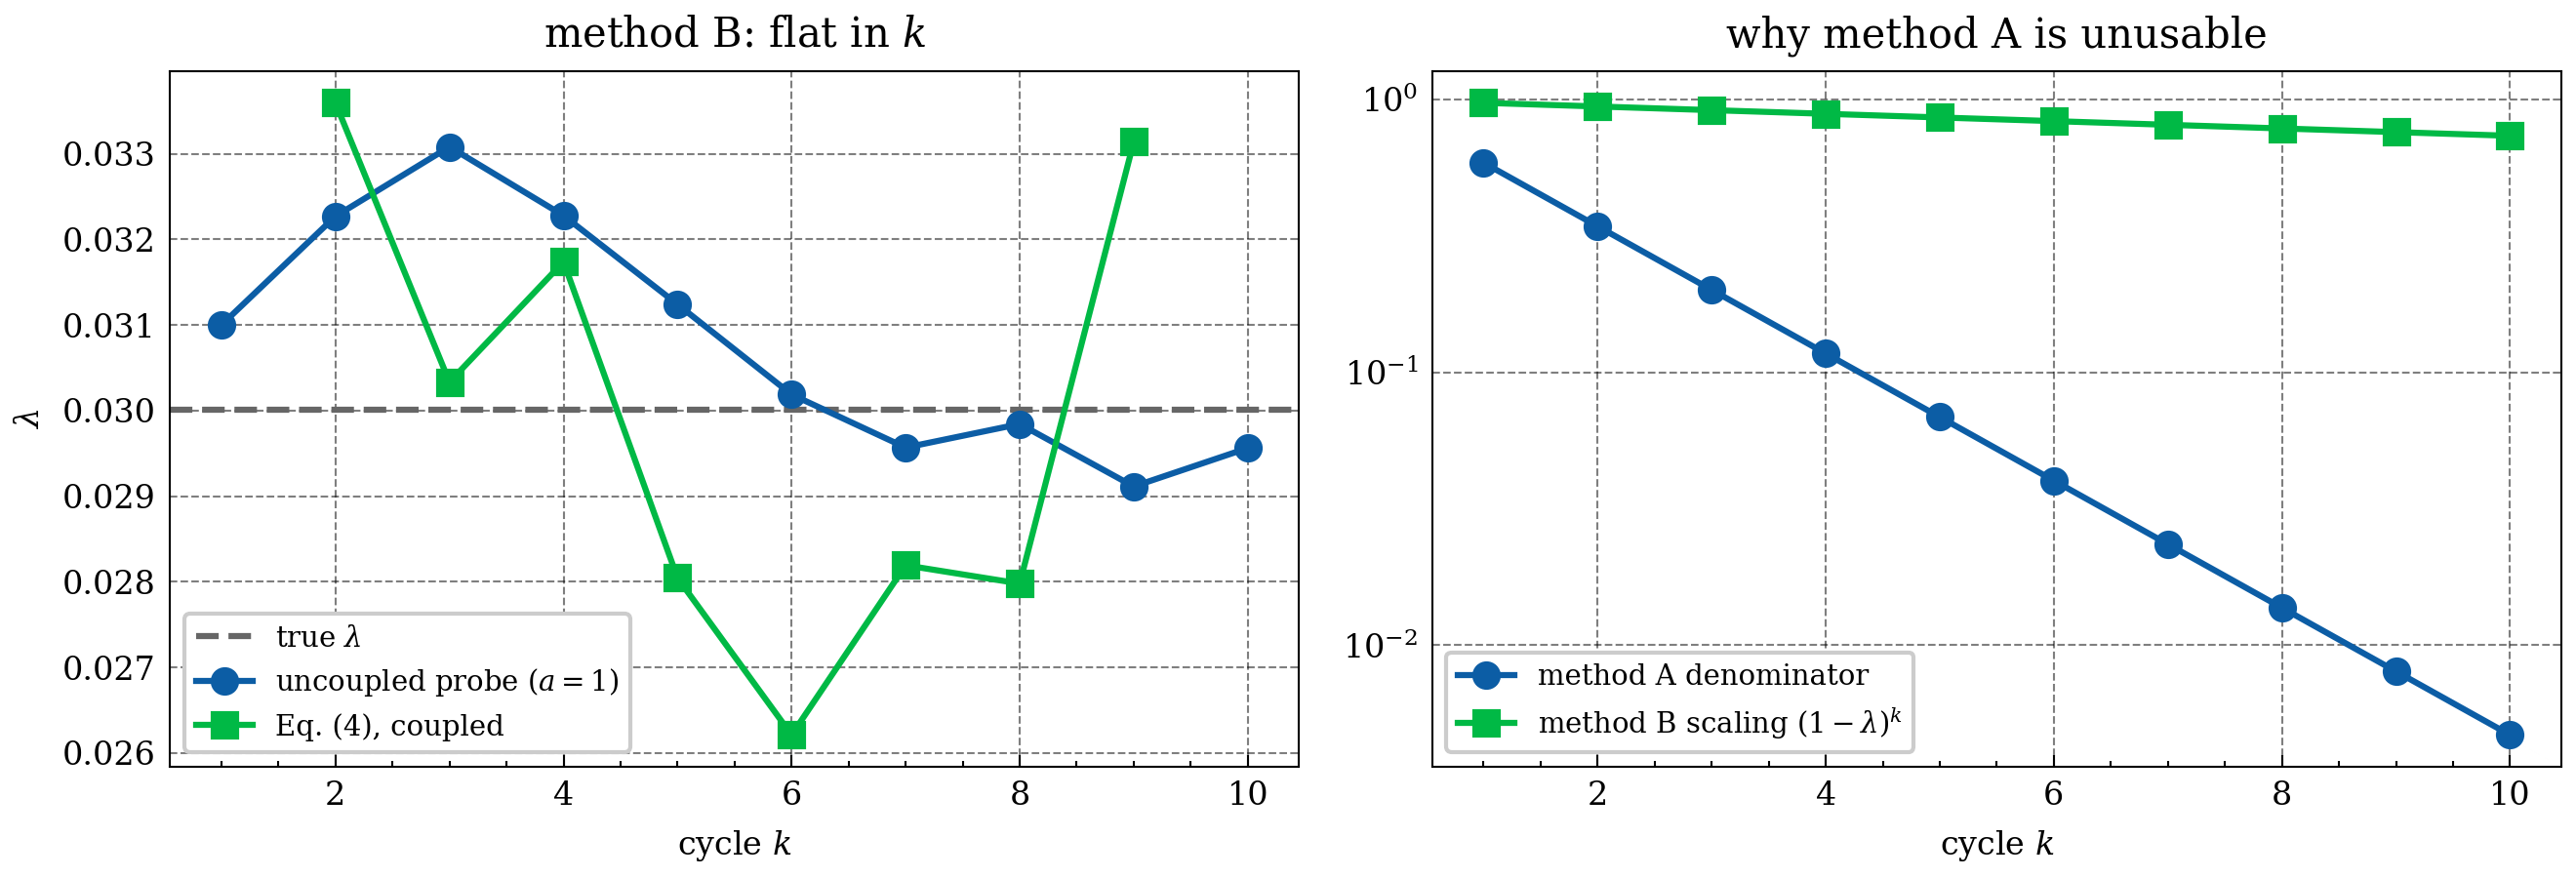

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))

axes[0].axhline(LAMBDA, color="0.4", ls="--", label="true $\\lambda$")
axes[0].plot(cycles, uncoupled_lambdas, "o-", label="uncoupled probe ($a=1$)")
axes[0].plot(cycles[: len(coupled_lambdas)] + 1, coupled_lambdas, "s-", label="Eq. (4), coupled")
axes[0].set_xlabel("cycle $k$")
axes[0].set_ylabel("$\\lambda$")
axes[0].set_title("method B: flat in $k$")
axes[0].legend(fontsize=7)

axes[1].semilogy(cycles, np.cos(PHI) ** (2 * cycles), "o-", label="method A denominator")
axes[1].semilogy(cycles, (1 - LAMBDA_LEARNED) ** cycles, "s-",
                 label="method B scaling $(1-\\lambda)^k$")
axes[1].set_xlabel("cycle $k$")
axes[1].set_title("why method A is unusable")
axes[1].legend(fontsize=7)

plt.tight_layout()

## 5. Mitigation

Three stages, per site:

1. **shift** — $\rho_{\rm shift}=\rho_{\rm phys}-\rho_{\rm abs}$, both at the same $\Omega$
2. **scaling** — $S_k=(1-\lambda)^k$, from §4
3. **unattenuate** — $\rho_{\rm corr}=\rho_{\rm shift}/S_k$

$S_k$ is a repeated attenuation, so it lies in $(0,1]$; values outside are masked rather than divided by,
since they mean the calibration at that depth was noise-dominated rather than measured.

  k   ideal    noisy    mitigated   |noisy-ideal|  |mitigated-ideal|
  1   0.5246   0.5238   0.5253      0.0007         0.0007
  2   0.2907   0.3002   0.2903      0.0095         0.0004
  3   0.2790   0.2856   0.2753      0.0066         0.0038
  4   0.2796   0.2829   0.2710      0.0033         0.0086
  5   0.2467   0.2545   0.2400      0.0078         0.0067
  6   0.2004   0.2145   0.1966      0.0141         0.0038
  7   0.1618   0.1830   0.1608      0.0212         0.0010
  8   0.1308   0.1561   0.1249      0.0253         0.0059
  9   0.1023   0.1343   0.0983      0.0320         0.0040
 10   0.0784   0.1154   0.0731      0.0370         0.0054

mean |error|: uncorrected 0.0158, mitigated 0.0040


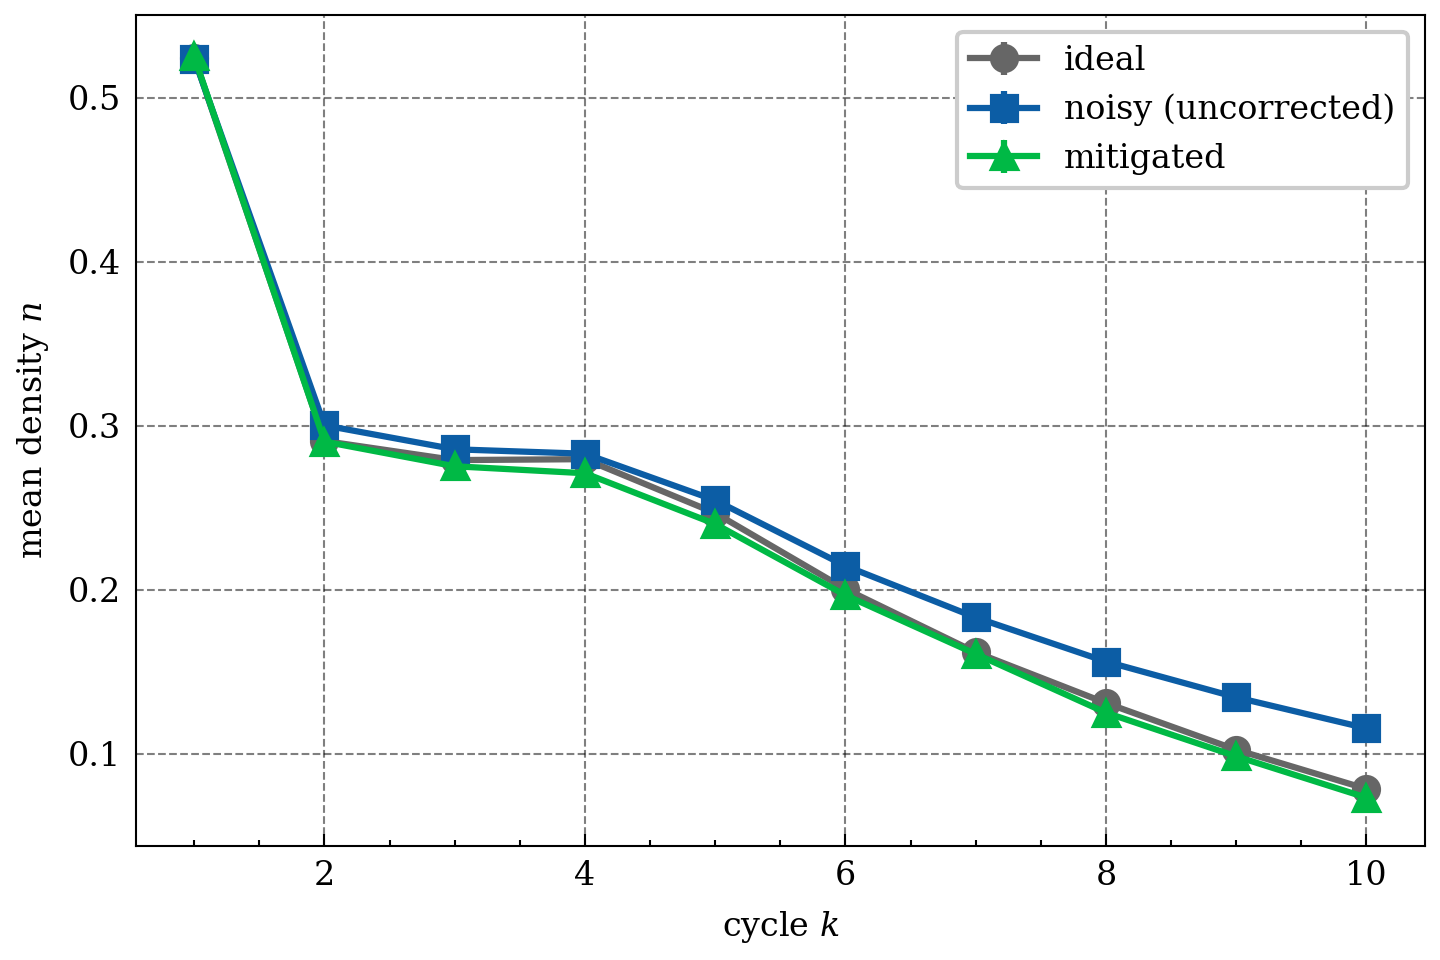

In [8]:
def unattenuate(shift, scaling, min_scaling=1e-3):
    """shift / scaling, masking scaling outside (min_scaling, 1] to NaN."""
    safe = np.where((scaling <= min_scaling) | (scaling > 1.0), np.nan, scaling)
    return shift / safe[:, None]


shift = phys - floor
shift_err = np.sqrt(phys_err**2 + floor_err**2)
scaling = (1.0 - LAMBDA_LEARNED) ** cycles

mitigated = unattenuate(shift, scaling)
mitigated_err = unattenuate(shift_err, scaling)

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.errorbar(cycles, ideal.mean(axis=1), yerr=ideal_err.mean(axis=1), fmt="o-",
            color="0.4", label="ideal")
ax.errorbar(cycles, phys.mean(axis=1), yerr=phys_err.mean(axis=1), fmt="s-",
            label="noisy (uncorrected)")
ax.errorbar(cycles, mitigated.mean(axis=1), yerr=mitigated_err.mean(axis=1), fmt="^-",
            label="mitigated")
ax.set_xlabel("cycle $k$")
ax.set_ylabel("mean density $n$")
ax.legend()
plt.tight_layout()

raw_gap = np.abs(phys.mean(axis=1) - ideal.mean(axis=1))
mitigated_gap = np.abs(mitigated.mean(axis=1) - ideal.mean(axis=1))
print("  k   ideal    noisy    mitigated   |noisy-ideal|  |mitigated-ideal|")
for k in range(NUM_CYCLES):
    print(f" {k + 1:2d}   {ideal.mean(axis=1)[k]:.4f}   {phys.mean(axis=1)[k]:.4f}   "
          f"{mitigated.mean(axis=1)[k]:.4f}      {raw_gap[k]:.4f}         {mitigated_gap[k]:.4f}")
print(f"\nmean |error|: uncorrected {raw_gap.mean():.4f}, mitigated {mitigated_gap.mean():.4f}")

## 6. Negative control: the unital shortcut

Were $\mathcal U$ unital, $\sigma^{(k)}$ would be exactly $\left(1-(1-\lambda)^k\right)I/d$, giving
$(1-\lambda)^k=1-2y^{(k)}_{\rm abs}$ at every site and the one-line correction

$$y_{\rm corrected}=\frac{y_{\rm phys}-y_{\rm abs}}{1-2\,y_{\rm abs}}$$

That is what you would write without any of the machinery above, and it is wrong here. Amplitude damping
pulls the depolarizing-injected identity toward $|0\cdots0\rangle$, so the measured floor is *smaller*
than the unital prediction; $1-2y_{\rm abs}$ therefore **over**-estimates the attenuation, the denominator
is too large, and the corrected curve bends below truth — worsening with depth.

**Catches:** the mitigation being trivially equivalent to the easy unital case.

unital shortcut bias: first cycle +0.0000, last -0.0167
correct method  bias: first cycle +0.0007, last -0.0054

mean |error|: unital 0.0118, correct 0.0040


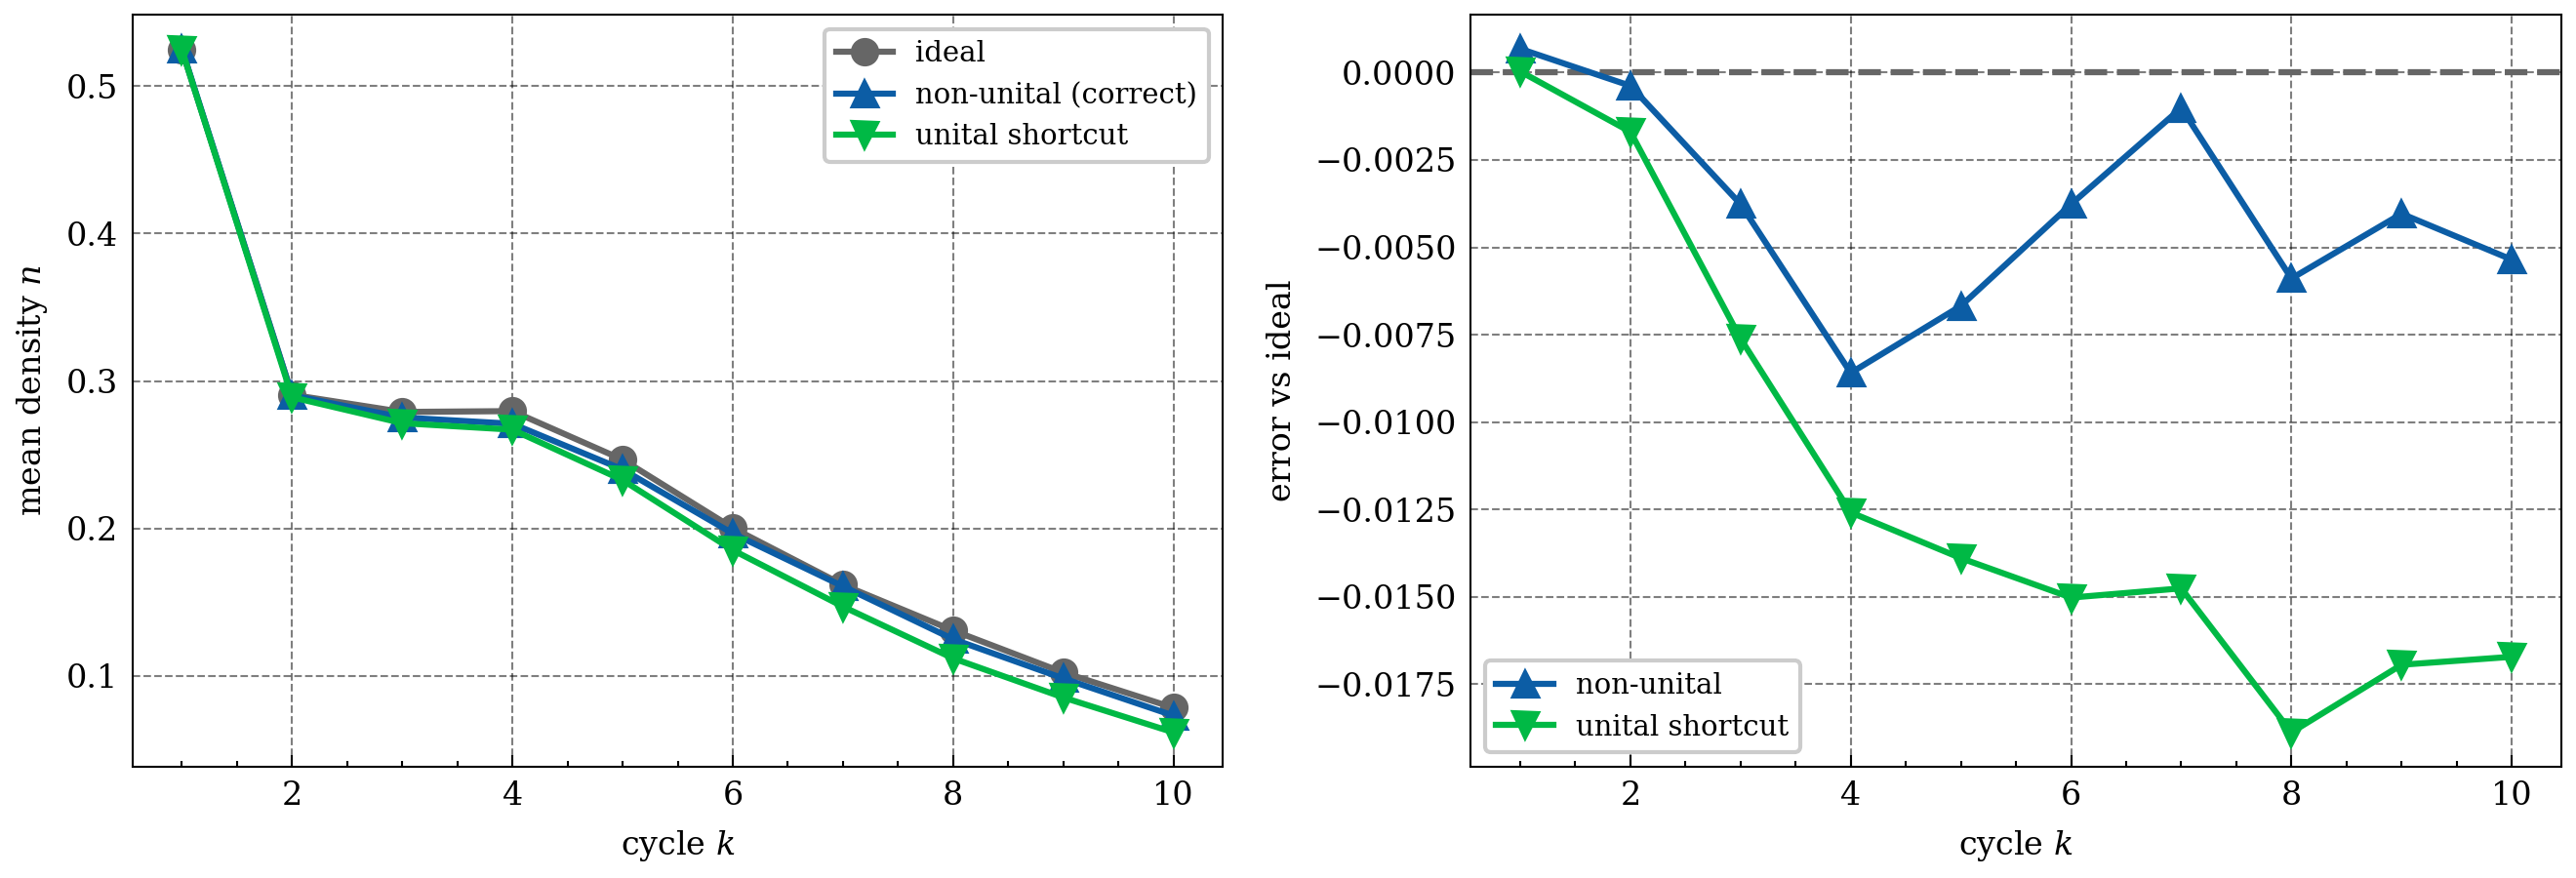

In [9]:
unital_scaling = 1.0 - 2.0 * floor
unital = np.where(unital_scaling > 1e-3, shift / unital_scaling, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].plot(cycles, ideal.mean(axis=1), "o-", color="0.4", label="ideal")
axes[0].plot(cycles, mitigated.mean(axis=1), "^-", label="non-unital (correct)")
axes[0].plot(cycles, unital.mean(axis=1), "v-", label="unital shortcut")
axes[0].set_xlabel("cycle $k$")
axes[0].set_ylabel("mean density $n$")
axes[0].legend(fontsize=7)

axes[1].axhline(0.0, color="0.4", ls="--")
axes[1].plot(cycles, mitigated.mean(axis=1) - ideal.mean(axis=1), "^-", label="non-unital")
axes[1].plot(cycles, unital.mean(axis=1) - ideal.mean(axis=1), "v-", label="unital shortcut")
axes[1].set_xlabel("cycle $k$")
axes[1].set_ylabel("error vs ideal")
axes[1].legend(fontsize=7)
plt.tight_layout()

unital_bias = unital.mean(axis=1) - ideal.mean(axis=1)
correct_bias = mitigated.mean(axis=1) - ideal.mean(axis=1)
print(f"unital shortcut bias: first cycle {unital_bias[0]:+.4f}, last {unital_bias[-1]:+.4f}")
print(f"correct method  bias: first cycle {correct_bias[0]:+.4f}, last {correct_bias[-1]:+.4f}")
print(f"\nmean |error|: unital {np.abs(unital_bias).mean():.4f}, "
      f"correct {np.abs(correct_bias).mean():.4f}")

## 7. The correction is unbiased

Trajectory sampling cannot demonstrate machine precision, so the precise claim is that the mitigated
estimator is **unbiased**: its residual against the ideal curve falls as $N^{-1/2}$, while the uncorrected
residual is a systematic that does not shrink with $N$ at all.

$\lambda$ is re-calibrated at each $N$ from a run of the same size, so the calibration error shrinks
alongside the sampling error — this measures the whole pipeline, not just the final division.

**Catches:** a mitigation that is merely *closer* rather than correct; a biased estimator would flatten
out instead of tracking $N^{-1/2}$.
**Does not catch:** the reference curve has its own shot noise, which puts a floor under the residual and
flattens the fit slightly at the largest $N$.

fitted slope -0.590   (unbiased => -0.5; reference shot noise flattens it)
at N = 4000: mitigated 0.0019, uncorrected 0.0201


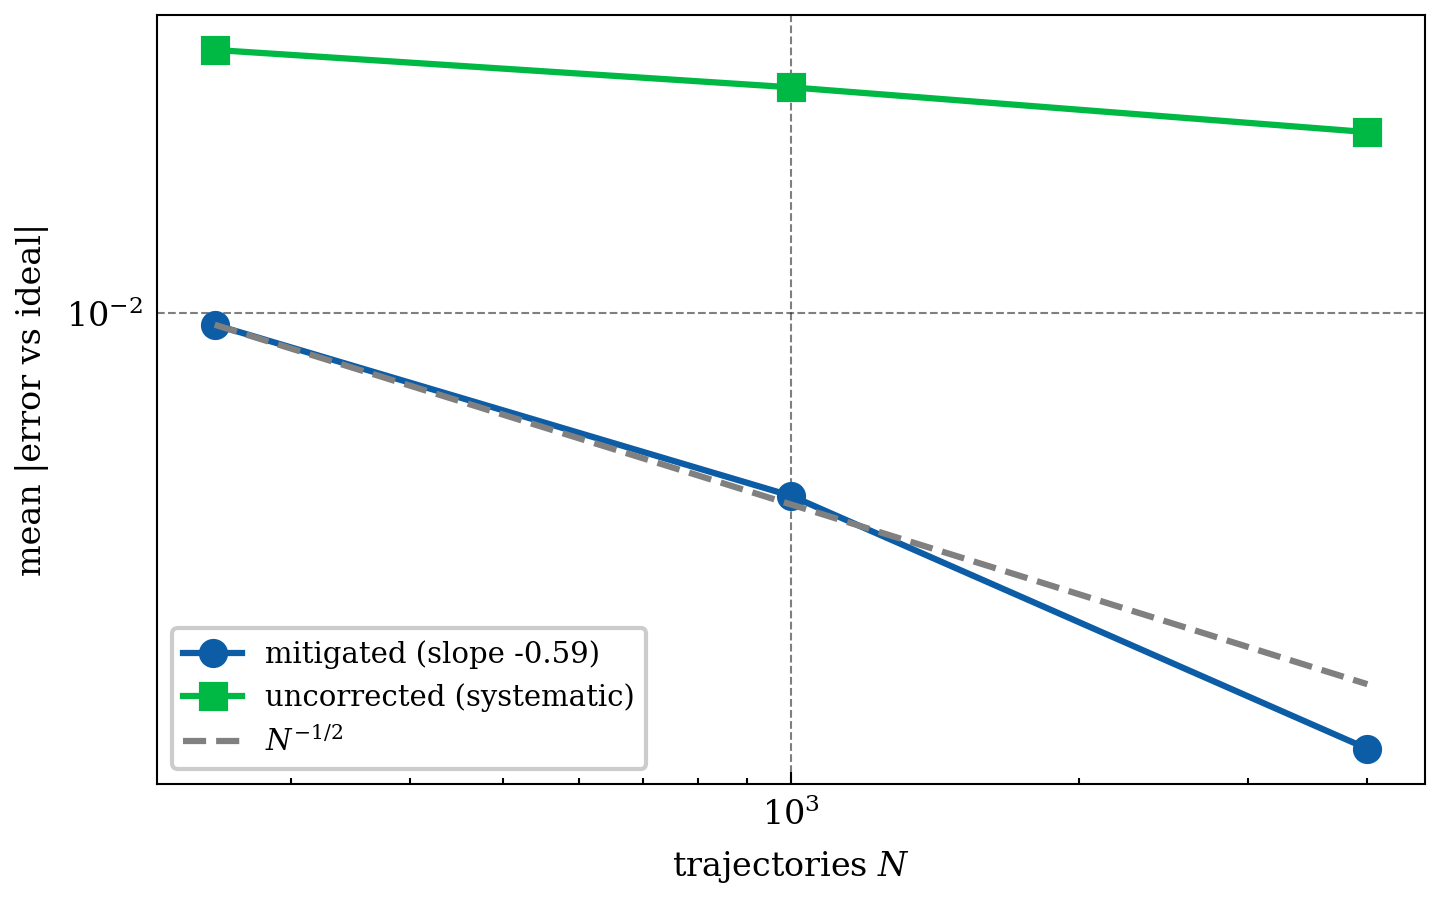

In [10]:
trajectory_counts = [250, 1000, 4000]
mitigated_residuals, raw_residuals = [], []

for count in trajectory_counts:
    learned, _, _ = learn_lambda(count, seed=101)
    phys_n, _ = run_density(qcp, EXCITED, count, seed=202, noise=noise)
    floor_n, _ = run_density(qcp, VACUUM, count, seed=202, noise=noise)
    corrected = unattenuate(phys_n - floor_n, (1.0 - learned) ** cycles)
    mitigated_residuals.append(np.abs(corrected.mean(axis=1) - ideal.mean(axis=1)).mean())
    raw_residuals.append(np.abs(phys_n.mean(axis=1) - ideal.mean(axis=1)).mean())

slope = np.polyfit(np.log(trajectory_counts), np.log(mitigated_residuals), 1)[0]

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.loglog(trajectory_counts, mitigated_residuals, "o-", label=f"mitigated (slope {slope:.2f})")
ax.loglog(trajectory_counts, raw_residuals, "s-", label="uncorrected (systematic)")
reference = mitigated_residuals[0] * (np.array(trajectory_counts) / trajectory_counts[0]) ** -0.5
ax.loglog(trajectory_counts, reference, "--", color="0.5", label="$N^{-1/2}$")
ax.set_xlabel("trajectories $N$")
ax.set_ylabel("mean |error vs ideal|")
ax.legend(fontsize=7)
plt.tight_layout()

print(f"fitted slope {slope:.3f}   (unbiased => -0.5; reference shot noise flattens it)")
print(f"at N = {trajectory_counts[-1]}: mitigated {mitigated_residuals[-1]:.4f}, "
      f"uncorrected {raw_residuals[-1]:.4f}")
assert mitigated_residuals[-1] < raw_residuals[-1] / 3, "mitigation should dominate at large N"

## 8. The variance price

The correction divides by $(1-\lambda)^k$, inflating the variance by $(1-\lambda)^{-2k}$. That is the cost
of the technique, and it sets the usable depth: the estimator stays unbiased, but its error bars grow
geometrically in the number of cycles.

variance inflation at k = 10: 1.9x
standard error 0.0046 -> 0.0063


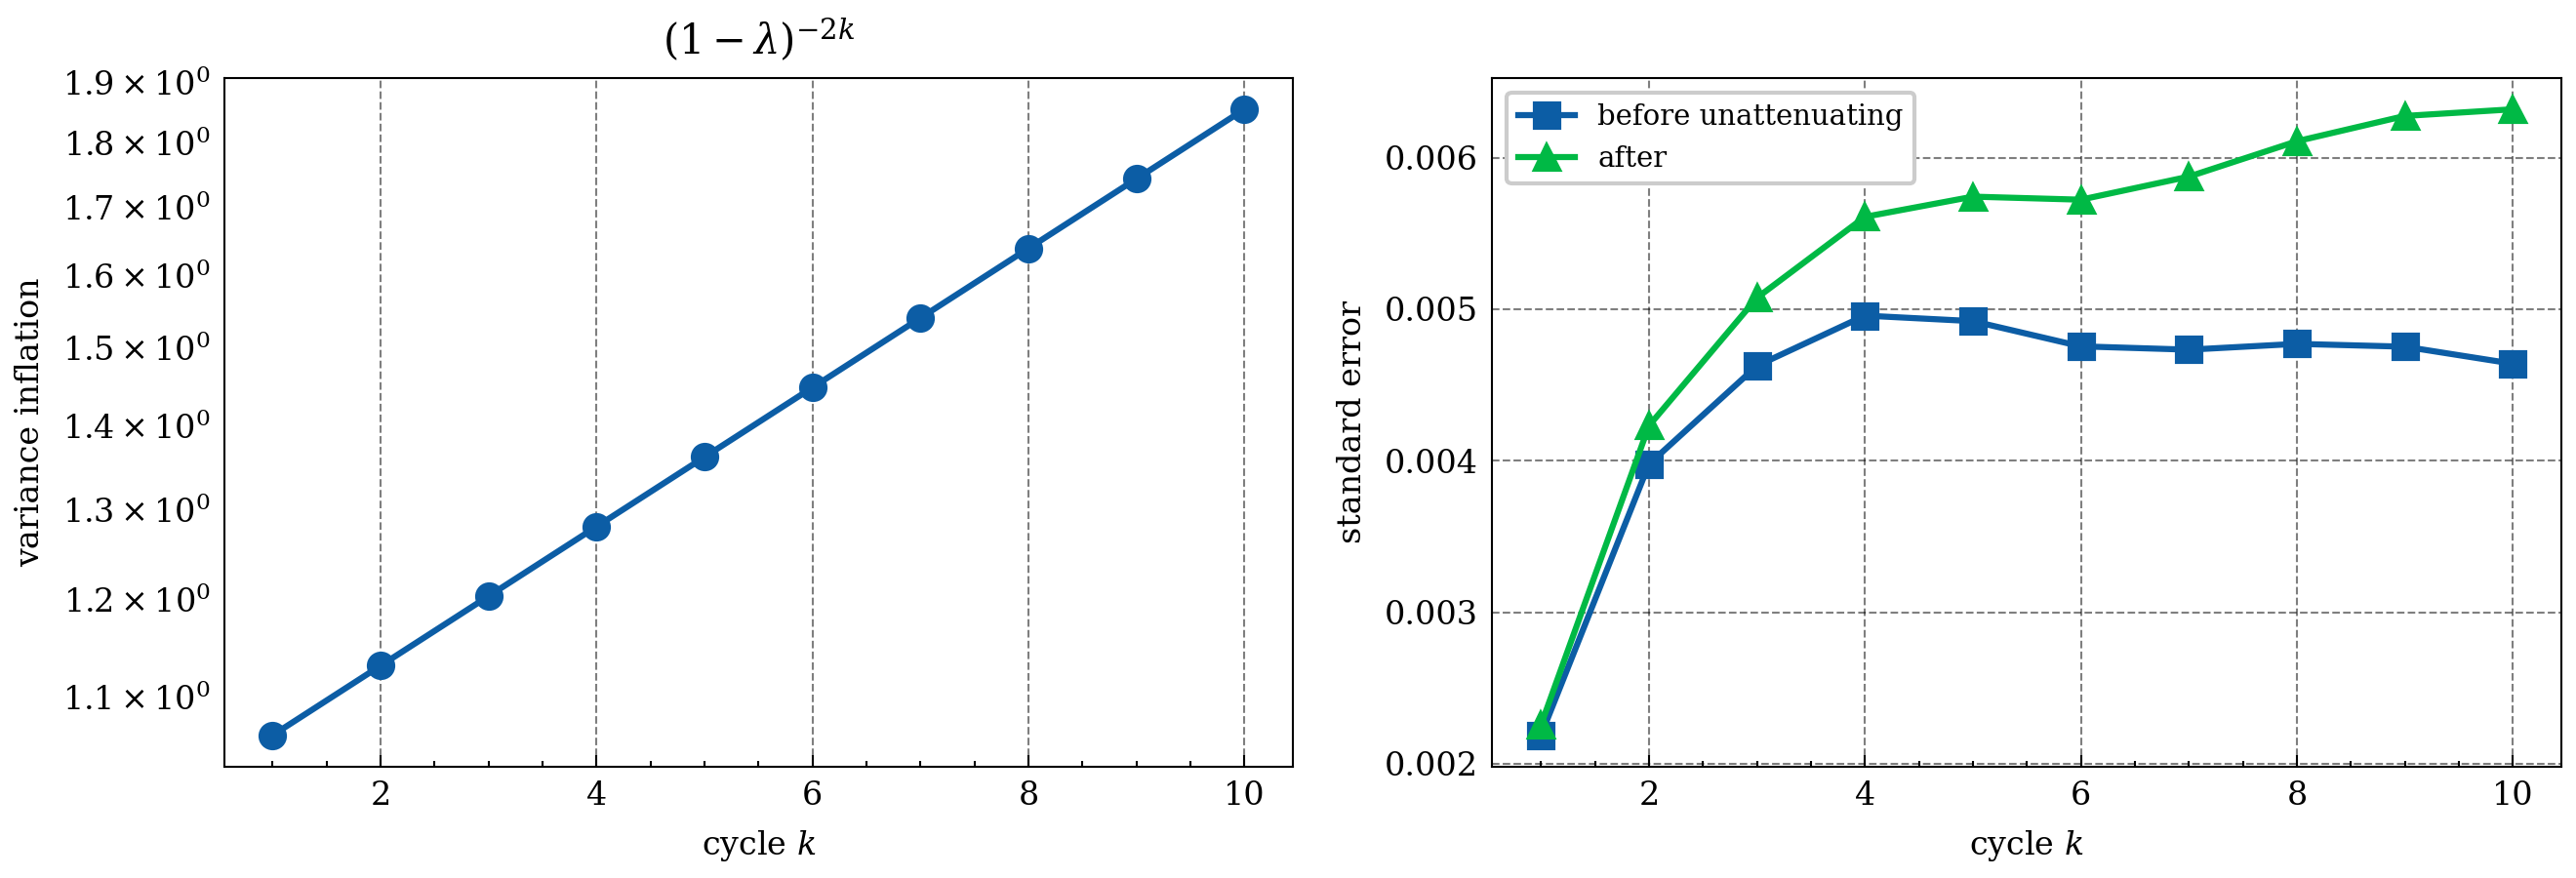

In [11]:
inflation = (1.0 - LAMBDA_LEARNED) ** (-2 * cycles)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].semilogy(cycles, inflation, "o-")
axes[0].set_xlabel("cycle $k$")
axes[0].set_ylabel("variance inflation")
axes[0].set_title("$(1-\\lambda)^{-2k}$")

axes[1].plot(cycles, shift_err.mean(axis=1), "s-", label="before unattenuating")
axes[1].plot(cycles, mitigated_err.mean(axis=1), "^-", label="after")
axes[1].set_xlabel("cycle $k$")
axes[1].set_ylabel("standard error")
axes[1].legend(fontsize=7)
plt.tight_layout()

print(f"variance inflation at k = {NUM_CYCLES}: {inflation[-1]:.1f}x")
print(f"standard error {shift_err.mean(axis=1)[-1]:.4f} -> {mitigated_err.mean(axis=1)[-1]:.4f}")

## 9. Reference test: exact inversion on a synthetic model

Sampling caps how precisely the sections above can test the *algebra*. Building the signals from the model
directly removes sampling entirely, so the pipeline must invert them to solver precision.

**Catches:** the inversion algebra, the Eq. (4) bisection, and the sign of the unital method's bias.
**Does not catch:** whether trajectory sampling is unbiased (§7's job), or whether global depolarizing
describes real hardware.

In [12]:
def reference_test(tolerance=1e-9):
    """Invert an exactly constructed absorbing floor and physical signal."""
    lam, survival = 0.08, np.cos(0.6) ** 2
    depths = np.arange(1, 9)

    absorbing = np.empty(len(depths))
    previous = 0.0
    for index in range(len(depths)):
        previous = (1 - lam) * survival * previous + lam / 2
        absorbing[index] = previous

    ideal_signal = 0.7 * (0.85**depths)
    physical = (1 - lam) ** depths * ideal_signal + absorbing

    solved = np.array([
        solve_lambda_pair(absorbing[k], absorbing[k + 2], survival)
        for k in range(len(depths) - 2)
    ])
    lambda_error = np.max(np.abs(solved - lam))
    assert lambda_error < tolerance, f"Eq (4) inversion failed: {lambda_error:.2e}"

    recovered = (physical - absorbing) / (1 - lam) ** depths
    recovery_error = np.max(np.abs(recovered - ideal_signal))
    assert recovery_error < tolerance, f"identity inversion failed: {recovery_error:.2e}"

    unital_bias = (physical - absorbing) / (1 - 2 * absorbing) - ideal_signal

    print(f"Eq (4) recovers lambda     max error {lambda_error:.2e}  (PASS, tol {tolerance:g})")
    print(f"identity recovers y_ideal  max error {recovery_error:.2e}  (PASS)")
    print("\nunital shortcut bias by depth:")
    for depth, bias in zip(depths, unital_bias):
        print(f"   k={depth}: {bias:+.4f}")
    # At k=1 the floor is exactly lambda/2, so 1 - 2 y_abs = 1 - lambda is the true scaling and
    # the two methods coincide. They separate from k=2, where the floor stops being unital.
    assert abs(unital_bias[0]) < tolerance, "the two must agree at k=1"
    assert unital_bias[-1] < unital_bias[1] < 0, "unital shortcut should bend below truth"


reference_test()

Eq (4) recovers lambda     max error 1.39e-17  (PASS, tol 1e-09)
identity recovers y_ideal  max error 5.55e-17  (PASS)

unital shortcut bias by depth:
   k=1: +0.0000
   k=2: -0.0136
   k=3: -0.0306
   k=4: -0.0457
   k=5: -0.0567
   k=6: -0.0636
   k=7: -0.0667
   k=8: -0.0670


## Summary

- The collisional cycle is non-unital because measure+reset sends $I/2\mapsto|0\rangle\langle0|$, so the
  one-line unital correction bends below truth and worsens with depth (§6).
- Subtracting an absorbing-state run cancels $\sigma^{(k)}$ exactly, leaving $(1-\lambda)^ky_{\rm ideal}$.
- $(1-\lambda)^k$ is recoverable from the $\Omega=0$ absorbing run alone — an $O(1)$ measurement — via
  Eq. (4) on coupled sites and $1-2y_{\rm abs}$ on uncoupled ones. Method A's denominator is $\sim10^{-6}$
  by $k=10$ and is unusable (§4).
- The resulting estimator is unbiased, converging as $N^{-1/2}$ (§7), at a variance cost of
  $(1-\lambda)^{-2k}$ that sets the usable depth (§8).

The assumption tested nowhere here is the one that matters on hardware: that the noise really is global,
state-independent and cycle-independent depolarizing. Everything above builds it in by construction.